# การจำแนกพันธุ์ Iris ด้วย KNN และวิธี Ensemble

งานนี้เปรียบเทียบ **KNN แบบทั่วไป** กับ **KNN Ensemble แบบสุ่มชุดคุณลักษณะ**
เพื่อดูว่าการรวมหลายโมเดลที่มองข้อมูลคนละมุมช่วยเพิ่มความแม่นยำหรือไม่

- Dataset: `Iris` จาก scikit-learn
- จำนวนข้อมูล: 150 ตัวอย่าง
- Features: 4 ค่า
- Classes: setosa, versicolor, virginica
- วิธีประเมิน: Accuracy, Confusion Matrix และการทดสอบหลาย seed

## 1. นำเข้าไลบรารี

ส่วนนี้เตรียมเครื่องมือสำหรับจัดการข้อมูล, สร้างโมเดล KNN,
แบ่งชุดฝึก–ทดสอบ และวัดผลการทำนาย

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib import font_manager

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

font_path = r"C:\Windows\Fonts\tahoma.ttf"
if Path(font_path).exists():
    font_manager.fontManager.addfont(font_path)
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=font_path).get_name()
else:
    plt.rcParams["font.family"] = "Tahoma"

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.edgecolor": "#AAB2BD",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.color": "#DCE3EA",
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.65,
    "figure.facecolor": "white",
    "axes.facecolor": "#FCFDFF",
    "axes.unicode_minus": False,
})

NAVY = "#31558C"
ORANGE = "#F0A15B"
TEAL = "#4F9D96"
LIGHT_BLUE = "#AFC5DE"
INK = "#263238"
BASE_SEED = 42


## 2. โหลดและตรวจสอบข้อมูล Iris

Iris มี 150 แถวและ 4 ฟีเจอร์ ได้แก่ ความยาว/ความกว้างของกลีบเลี้ยง
และความยาว/ความกว้างของกลีบดอก ส่วนคอลัมน์ `species`
คือคลาสที่โมเดลต้องจำแนก

In [2]:
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = pd.Categorical.from_codes(iris.target, iris.target_names)

print("รูปทรงข้อมูล:", df.shape)
print("\nข้อมูลสรุป:")
display(df.describe())
print("\nจำนวนแต่ละสายพันธุ์:")
print(df["species"].value_counts().sort_index())

รูปทรงข้อมูล: (150, 5)

ข้อมูลสรุป:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



จำนวนแต่ละสายพันธุ์:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## 3. สำรวจความสัมพันธ์ของฟีเจอร์

กราฟ pairplot ช่วยดูว่า feature คู่ใดแยกสายพันธุ์ได้ชัด
แต่ละสีแทนคนละ species และจุดที่เหมือนกันจะแสดงแนวโน้มให้ KNN ใช้หาเพื่อนบ้านได้

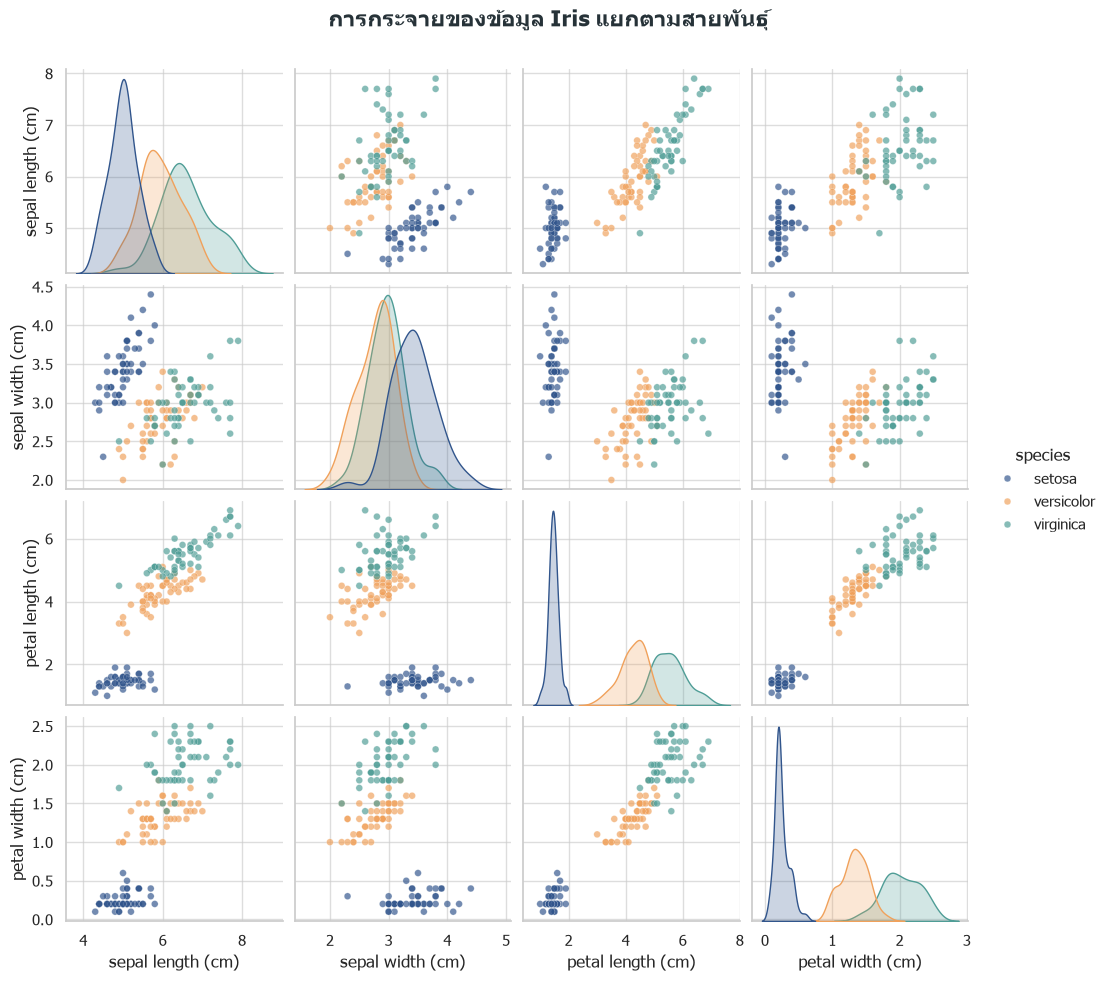

In [3]:
import seaborn as sns

palette = {"setosa": NAVY, "versicolor": ORANGE, "virginica": TEAL}
sns.set_theme(style="whitegrid", font=plt.rcParams["font.family"])

pair = sns.pairplot(
    df,
    hue="species",
    palette=palette,
    diag_kind="kde",
    plot_kws={"alpha": 0.68, "s": 24, "edgecolor": "white", "linewidth": 0.25},
)
pair.fig.subplots_adjust(top=0.92)
pair.fig.suptitle("การกระจายของข้อมูล Iris แยกตามสายพันธุ์",
                  fontsize=16, fontweight="bold", color=INK)
pair.savefig("iris_output/pairplot.png", dpi=220, bbox_inches="tight")
plt.show()


## 4. แบ่งข้อมูล Train / Test

ใช้สัดส่วน 80/20 พร้อม `stratify`
เพื่อให้ทั้งสองชุดมีสัดส่วนทั้ง 3 คลาสใกล้เคียงกัน

เนื่องจาก KNN ใช้ระยะทางระหว่างข้อมูล จึงใช้ `StandardScaler`
เพื่อปรับมาตราส่วนของฟีเจอร์ โดยคำนวณ scaler จาก Train เท่านั้น

In [4]:
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=BASE_SEED,
    stratify=y,
)

print("จำนวนชุดฝึก:", X_train.shape[0])
print("จำนวนชุดทดสอบ:", X_test.shape[0])
print("จำนวนฟีเจอร์:", X_train.shape[1])

จำนวนชุดฝึก: 120
จำนวนชุดทดสอบ: 30
จำนวนฟีเจอร์: 4


## 5. สร้างโมเดล KNN แบบอ้างอิง

Baseline นี้เป็น Pipeline ที่มี StandardScaler และ KNeighborsClassifier
แบบ `k=5` และให้น้ำหนัก inverse-distance เพื่อไม่ให้แค่จำนวนน้องบ้านกำหนดผลลัพธ์เท่ากันทุกจุด

In [5]:
baseline = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5, weights="distance"),
)
baseline.fit(X_train, y_train)

baseline_prediction = baseline.predict(X_test)
baseline_accuracy = accuracy_score(y_test, baseline_prediction)

print(f"Accuracy ของโมเดลอ้างอิง: {baseline_accuracy:.2%}")

Accuracy ของโมเดลอ้างอิง: 96.67%


## 6. สร้าง KNN Ensemble แบบสุ่มชุดฟีเจอร์

แต่ละโมเดลสมาชิกจะเลือก features สุ่ม 3 จาก 4 ค่า
ดังนั้นแต่ละโมเดลจะมองข้อมูลมุมต่างกัน จากนั้นใช้ **majority vote**
เพื่อรวมคำทำนายสุดท้าย

วิธีนี้แตกต่างจากการใช้ KNN ชุดเดียวบนข้อมูลครบทุกฟีเจอร์

In [6]:
class RandomSubspaceKNN:
    def __init__(self, member_count=9, k_neighbors=5, seed=42):
        self.member_count = member_count
        self.k_neighbors = k_neighbors
        self.seed = seed

    def fit(self, X, y):
        rng = np.random.default_rng(self.seed)
        self.member_models = []
        self.selected_features = []

        for _ in range(self.member_count):
            features = rng.choice(X.shape[1], size=3, replace=False)
            model = make_pipeline(
                StandardScaler(),
                KNeighborsClassifier(
                    n_neighbors=self.k_neighbors,
                    weights="distance",
                ),
            )
            model.fit(X[:, features], y)
            self.member_models.append(model)
            self.selected_features.append(features)

        return self

    def predict(self, X):
        all_votes = np.column_stack([
            model.predict(X[:, features])
            for model, features in zip(
                self.member_models,
                self.selected_features,
            )
        ])

        winners = []
        for row in all_votes:
            labels, counts = np.unique(row, return_counts=True)
            winners.append(labels[np.argmax(counts)])
        return np.array(winners)


ensemble = RandomSubspaceKNN(
    member_count=9,
    k_neighbors=5,
    seed=BASE_SEED,
).fit(X_train, y_train)

ensemble_prediction = ensemble.predict(X_test)
ensemble_accuracy = accuracy_score(y_test, ensemble_prediction)

print(f"Accuracy ของ Ensemble: {ensemble_accuracy:.2%}")

Accuracy ของ Ensemble: 90.00%


## 7. เปรียบเทียบผลลัพธ์ด้วยกราฟ

กราฟนี้เปรียบเทียบคะแนนของโมเดลอ้างอิงและ Ensemble
โดยใช้แกนเป็น 0 ถึง 100% เพื่ออ่านความแตกต่างได้ตรงไปตรงมา

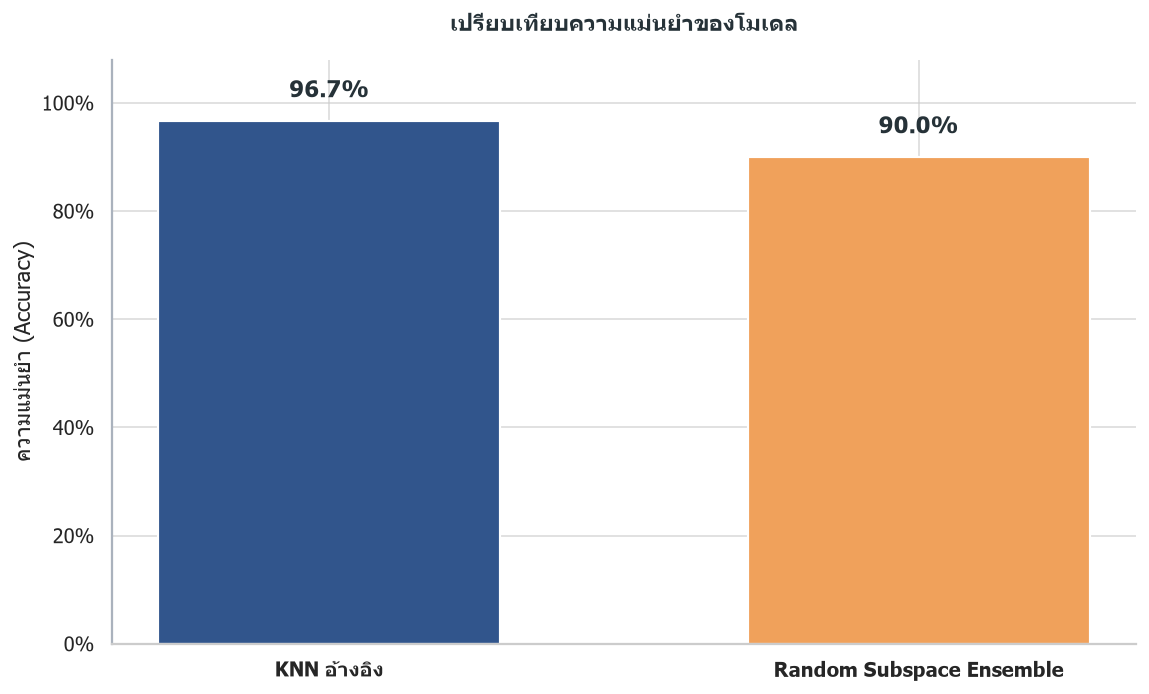

วิธี,Accuracy
KNN อ้างอิง,96.67%
Random Subspace Ensemble,90.00%


In [7]:
comparison = pd.DataFrame({
    "วิธี": ["KNN อ้างอิง", "Random Subspace Ensemble"],
    "Accuracy": [baseline_accuracy, ensemble_accuracy],
})

fig, ax = plt.subplots(figsize=(9, 5.5), dpi=130)
x = np.arange(len(comparison))
colors = [NAVY, ORANGE]
bars = ax.bar(x, comparison["Accuracy"], width=0.58, color=colors,
              edgecolor="#FFFFFF", linewidth=1.2)

ax.set_xticks(x)
ax.set_xticklabels(comparison["วิธี"], fontweight="bold")
ax.set_ylim(0, 1.08)
ax.set_ylabel("ความแม่นยำ (Accuracy)")
ax.set_title("เปรียบเทียบความแม่นยำของโมเดล", pad=16, color=INK)

for bar, score in zip(bars, comparison["Accuracy"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        min(score + 0.035, 1.045),
        f"{score:.1%}",
        ha="center",
        va="bottom",
        fontsize=13,
        fontweight="bold",
        color=INK,
    )

ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
ax.spines["left"].set_color("#AAB2BD")

fig.tight_layout()
fig.savefig("iris_output/accuracy_comparison.png", dpi=220, bbox_inches="tight")
plt.show()
display(comparison.style.format({"Accuracy": "{:.2%}"}).hide(axis="index"))


## 8. รายงาน Confusion Matrix

Confusion Matrix แสดงจำนวนตัวอย่างที่ทำนายถูกและผิดแยกตามคลาส
- แถว: คลาสจริง
- คอลัมน์: คลาสที่โมเดลทำนาย
- ค่าบนเส้นทแยงหลัก: ตัวอย่างที่ทำนายถูก

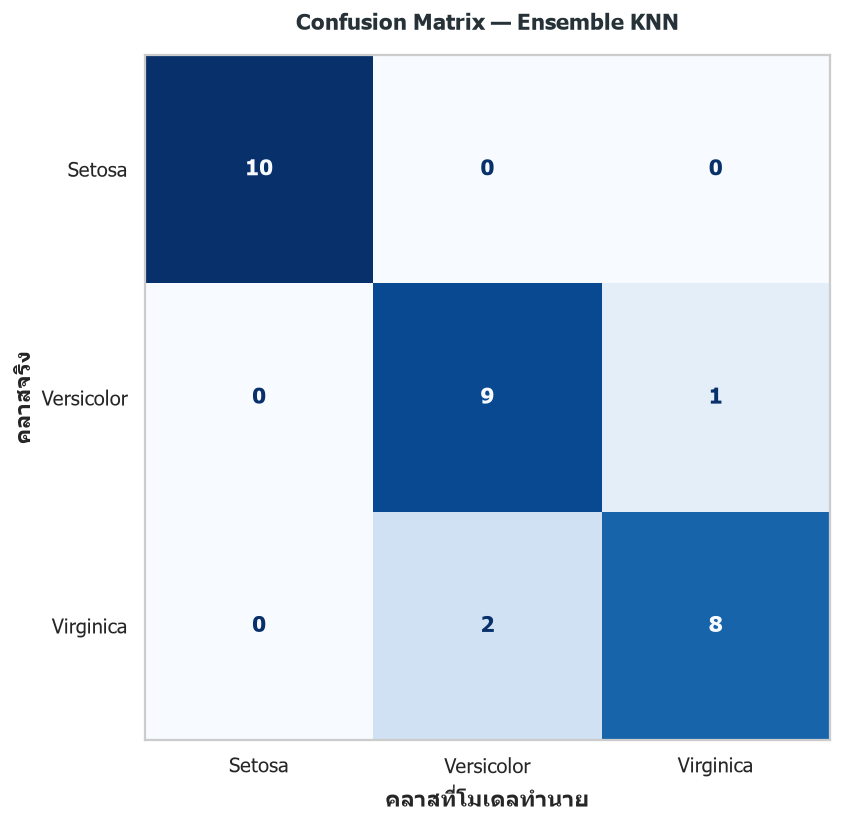

In [8]:
matrix = confusion_matrix(y_test, ensemble_prediction)
labels = ["Setosa", "Versicolor", "Virginica"]

fig, ax = plt.subplots(figsize=(8, 6.5), dpi=130)
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=labels,
)
display_matrix.plot(
    cmap="Blues",
    ax=ax,
    colorbar=False,
    values_format="d",
)

ax.set_title("Confusion Matrix — Ensemble KNN", pad=14, color=INK)
ax.set_xlabel("คลาสที่โมเดลทำนาย", fontweight="bold")
ax.set_ylabel("คลาสจริง", fontweight="bold")
ax.grid(False)

for text in ax.texts:
    text.set_fontweight("bold")
    text.set_fontsize(12)

fig.tight_layout()
fig.savefig("iris_output/confusion_matrix.png", dpi=220, bbox_inches="tight")
plt.show()


## 9. ทดสอบผลหลายค่า seed

ส่วนนี้รันการแบ่งข้อมูลและ Ensemble ซ้ำ 30 ครั้ง
เพื่อดูว่าคะแนนผันแปรมากน้อยเพียงใด โดยไม่ใช้ข้อมูลทดสอบเพื่อปรับโมเดล

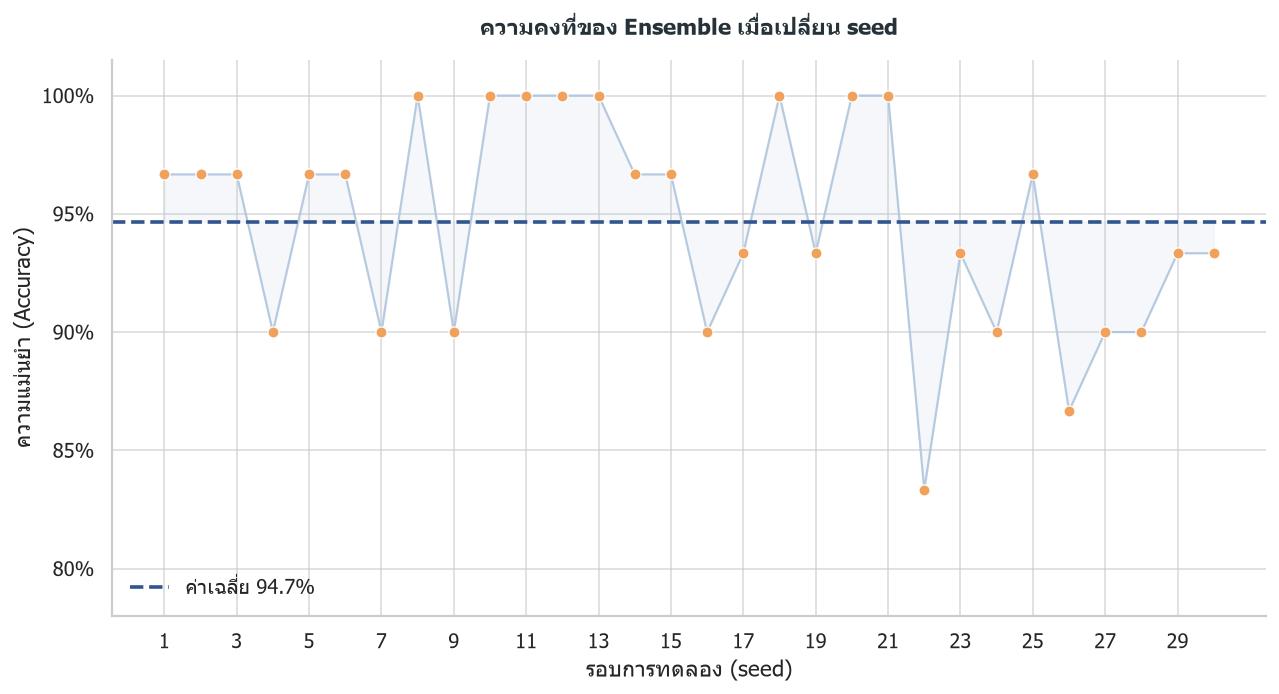

ค่าเฉลี่ย: 94.67%
ต่ำสุด: 83.33%
สูงสุด: 100.00%


In [9]:
seed_scores = []

for seed in range(30):
    loop_train, loop_test, loop_train_y, loop_test_y = train_test_split(
        X, y, test_size=0.20, random_state=seed, stratify=y
    )
    loop_model = RandomSubspaceKNN(
        member_count=9,
        k_neighbors=5,
        seed=seed,
    ).fit(loop_train, loop_train_y)
    loop_pred = loop_model.predict(loop_test)
    seed_scores.append(accuracy_score(loop_test_y, loop_pred))

mean_score = np.mean(seed_scores)
min_score = np.min(seed_scores)
max_score = np.max(seed_scores)

fig, ax = plt.subplots(figsize=(10, 5.5), dpi=130)
runs = np.arange(1, 31)

ax.fill_between(runs, seed_scores, mean_score, alpha=0.12, color=LIGHT_BLUE)
ax.plot(runs, seed_scores, color=LIGHT_BLUE, linewidth=1.2, alpha=0.9)
ax.scatter(runs, seed_scores, s=38, color=ORANGE, edgecolor="white",
           linewidth=0.7, zorder=3)
ax.axhline(mean_score, color=NAVY, linestyle="--", linewidth=2,
           label=f"ค่าเฉลี่ย {mean_score:.1%}")

ax.set_xlabel("รอบการทดลอง (seed)")
ax.set_ylabel("ความแม่นยำ (Accuracy)")
ax.set_ylim(0.78, 1.015)
ax.set_xticks(np.arange(1, 31, 2))
ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
ax.set_title("ความคงที่ของ Ensemble เมื่อเปลี่ยน seed", pad=14, color=INK)
ax.legend(loc="lower left", frameon=False)

for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)

fig.tight_layout()
fig.savefig("iris_output/seed_stability.png", dpi=220, bbox_inches="tight")
plt.show()

print(f"ค่าเฉลี่ย: {mean_score:.2%}")
print(f"ต่ำสุด: {min_score:.2%}")
print(f"สูงสุด: {max_score:.2%}")


## 10. สรุปผล

- ชุดข้อมูลถูกแบ่ง Train/Test อย่างชัดเจนและใช้ stratified sampling
- StandardScaler ช่วยทำให้ระยะทางของ KNN เท่าเทียมกัน
- Random-subspace Ensemble ฝึกโมเดล KNN หลายตัวบน feature subset คนละชุด
- ผลทำนายสุดท้ายใช้ majority vote
- ต้องเปรียบเทียบกับคะแนน baseline และผลซ้ำหลาย seed
  จึงสรุปว่าระบบคงที่หรือดีขึ้นจริง

## 11. บันทึกผลลัพธ์และกราฟ

ส่วนนี้บันทึกคะแนนสรุป, ผลทำนายรายตัวอย่าง และกราฟเปรียบเทียบ
ลงในโฟลเดอร์ `iris_output` เพื่อใช้ต่อในรายงานหรือส่งไฟล์ได้ทันที

In [10]:
from pathlib import Path
import pandas as pd
import numpy as np

output_dir = Path("iris_output")
output_dir.mkdir(parents=True, exist_ok=True)

predictions = pd.DataFrame({
    "sample": np.arange(len(y_test)),
    "actual": [iris.target_names[value] for value in y_test],
    "ensemble_predicted": [iris.target_names[value] for value in ensemble_prediction],
    "baseline_predicted": [iris.target_names[value] for value in baseline_prediction],
})
predictions["ensemble_correct"] = (
    predictions["actual"] == predictions["ensemble_predicted"]
)
predictions["baseline_correct"] = (
    predictions["actual"] == predictions["baseline_predicted"]
)
predictions.to_csv(
    output_dir / "test_predictions.csv",
    index=False,
    encoding="utf-8-sig",
)

summary_lines = [
    "สรุปผลการทดลอง Random-subspace KNN บน Iris",
    "=" * 55,
    f"จำนวนข้อมูลทั้งหมด: {len(X)}",
    f"จำนวนชุดฝึก: {len(X_train)}",
    f"จำนวนชุดทดสอบ: {len(X_test)}",
    f"Accuracy ของ KNN อ้างอิง: {baseline_accuracy:.2%}",
    f"Accuracy ของ Ensemble: {ensemble_accuracy:.2%}",
    f"Accuracy Ensemble เฉลี่ย 30 seed: {np.mean(seed_scores):.2%}",
    f"Accuracy Ensemble ต่ำสุด: {np.min(seed_scores):.2%}",
    f"Accuracy Ensemble สูงสุด: {np.max(seed_scores):.2%}",
]
summary_path = output_dir / "summary.txt"
summary_path.write_text("\n".join(summary_lines), encoding="utf-8")

print(summary_path.read_text(encoding="utf-8"))
print("บันทึกผลแล้วที่:", output_dir.resolve())
print(sorted(item.name for item in output_dir.iterdir()))


สรุปผลการทดลอง Random-subspace KNN บน Iris
จำนวนข้อมูลทั้งหมด: 150
จำนวนชุดฝึก: 120
จำนวนชุดทดสอบ: 30
Accuracy ของ KNN อ้างอิง: 96.67%
Accuracy ของ Ensemble: 90.00%
Accuracy Ensemble เฉลี่ย 30 seed: 94.67%
Accuracy Ensemble ต่ำสุด: 83.33%
Accuracy Ensemble สูงสุด: 100.00%
บันทึกผลแล้วที่: C:\Users\Administrator\Downloads\Ensemble_knn_iris-main\Ensemble_knn_iris-main\iris_output
['accuracy_comparison.png', 'confusion_matrix.png', 'pairplot.png', 'seed_stability.png', 'summary.txt', 'test_predictions.csv']
